In [ ]:
# Initialize notebook

# %matplotlib notebook
from __future__ import annotations

%matplotlib widget
# %matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

In [2]:
def Rot_Matrix(axis, theta, IsRadian=True):
    """>>> Instruction <<<
    Calculate a generic rotation matrix that makes a rotation of 'theta' around a given 'axis'.

    Inputs:
        'axis'     Rotation axis, format np.asarray([x, y, z])
        'theta'    Rotation angle

    Output:
        a 3-by-3 array

    In application, assuming that we need to rotate a vector Vi to a new direction Vf, then
        axis   = np.cross(Vi, Vf) / np.linalg.norm(np.cross(Vi, Vf))
        theta  = np.arccos( np.dot(Vi, Vf) / (np.linalg.norm(Vi) * np.linalg.norm(Vf)) )
    """
    if not IsRadian:
        theta = np.deg2rad(theta)

    if np.linalg.norm(axis) == 0:
        x, y, z = axis
    else:
        x, y, z = axis / np.linalg.norm(axis)
    c = np.cos(theta)
    s = np.sin(theta)
    C = 1 - c
    return np.matrix(
        [
            [x * x * C + c, x * y * C - z * s, x * z * C + y * s],
            [y * x * C + z * s, y * y * C + c, y * z * C - x * s],
            [z * x * C - y * s, z * y * C + x * s, z * z * C + c],
        ]
    )

In [3]:
def get_hBragg(delta, gamma, IsRadian=False):
    rot_mat = Rot_Matrix([-1.0, 0.0, 0.0], gamma, IsRadian=IsRadian)
    rot_mat = Rot_Matrix([0.0, 1.0, 0.0], delta, IsRadian=IsRadian) @ rot_mat
    ki = np.asarray([0.0, 0.0, 1.0])
    kh = np.squeeze(np.asarray(rot_mat @ ki))
    print(ki)
    print(kh)
    return kh - ki

In [10]:
def scat_geo_plotter(
    angles,
    beamline="cdi-nsls2",
    samp_ori_norm=[0.0, 1.0, 0.0],
    samp_ori_u=None,
    samp_ori_v=None,
    u_name=None,
    v_name=None,
    flag_inv_norm=False,
    flag_inv_inpl=False,
    flag_plot=True,
    flag_info=True,
):
    """This function draws the scattering geometery based on a set of angles.

    Inputs:
        - angles: a dictionary containing angle values, unit [deg]
            - For 'cdi-nsls2' (CDI beamline at NSLS2):
                {# Axes ordered from bottom to top, i.e., motion of a stage affects all ones on top.
                 # Goniometer axes (Translation axes are included for completeness but not used in the function.)
                 'Ty_JJ': 0.,
                 'Tz_JJ': 0.,
                 'Tx_JJ': 0.,
                 'Rz_JJ': 0.,
                 'Rx_JJ': 0.,
                 'Ry': 0.,
                 'Tz_L': 0.,
                 'Tx_L': 0.,
                 'Rx_TT_L': 0.,
                 'Rz_TT_L': 0.,
                 'Rx_TT_S': 0.,
                 'Rz_TT_S': 0.,
                 'Ty': 0.,
                 'Tx_S': 0.,
                 'Tz_S': 0.,
                 # TDMS axes
                 'AY': 0.,   # delta
                 'TZ': 0.,   # tower translation along arm
                 'AZ': 0.,
                 'TY': 0.,   # detector cage height
                 'TX': 0.,
                 'AX': 0.,   # gamma
                 }
        - beamline: select a predefined gonio setup of a beamline
        - samp_ori_norm: initial normal of a plane at the sample
            - if None, this is calculated based on the scattering geometery (i.e., detector location).
        - samp_ori_u / v: (optional) two in-plane axes at the sample
        - u / v_name: (optional) names of samp_ori_u / v axes.
        - flag_inv_norm: if True, samp_ori_norm is the FINAL normal
        - flag_inv_inpl: if True, samp_ori_u / v are the FINAL in-plane axes

    Output:
        - A 3D plot of the sample-detector geometery.
    """
    # calculate rotation matrices
    if beamline == "cdi-nsls2":
        srot_mat = np.eye(3)  # initial matrix
        srot_mat = (
            Rot_Matrix([0.0, 0.0, 1.0], angles["Rz_TT_S"], IsRadian=False) @ srot_mat
        )
        srot_mat = (
            Rot_Matrix([1.0, 0.0, 0.0], angles["Rx_TT_S"], IsRadian=False) @ srot_mat
        )
        srot_mat = (
            Rot_Matrix([0.0, 0.0, 1.0], angles["Rz_TT_L"], IsRadian=False) @ srot_mat
        )
        srot_mat = (
            Rot_Matrix([1.0, 0.0, 0.0], angles["Rx_TT_L"], IsRadian=False) @ srot_mat
        )
        srot_mat = Rot_Matrix([0.0, 1.0, 0.0], angles["Ry"], IsRadian=False) @ srot_mat
        srot_mat = (
            Rot_Matrix([1.0, 0.0, 0.0], angles["Rx_JJ"], IsRadian=False) @ srot_mat
        )
        srot_mat = (
            Rot_Matrix([0.0, 0.0, 1.0], angles["Rz_JJ"], IsRadian=False) @ srot_mat
        )

        drot_mat = np.eye(3)
        drot_mat = Rot_Matrix([-1.0, 0.0, 0.0], angles["AX"], IsRadian=False) @ drot_mat
        drot_mat = Rot_Matrix([0.0, 0.0, 1.0], angles["AZ"], IsRadian=False) @ drot_mat
        drot_mat = Rot_Matrix([0.0, 1.0, 0.0], angles["AY"], IsRadian=False) @ drot_mat
    else:
        raise ValueError("Undefined beamline.")
    # get sample vectors
    if samp_ori_norm is None:  # if None, using the momentum transfer vector
        samp_ori_norm = get_hBragg(angles["AY"], angles["AX"], IsRadian=False)
    samp_ori_norm /= np.linalg.norm(samp_ori_norm)
    if flag_inv_norm:
        fin_s_norm = samp_ori_norm
        ini_s_norm = np.squeeze(np.asarray(srot_mat.T @ fin_s_norm))
    else:
        ini_s_norm = samp_ori_norm
        fin_s_norm = np.squeeze(np.asarray(srot_mat @ ini_s_norm))
    if (samp_ori_u is None) and (samp_ori_v is None):
        if np.linalg.norm(np.cross([1.0, 0.0, 0.0], ini_s_norm)) == 0:
            samp_ori_u = np.asarray([0.0, 1.0, 0.0])
        else:
            samp_ori_u = np.asarray([1.0, 0.0, 0.0])
        samp_ori_v = np.cross(ini_s_norm, samp_ori_u)
        samp_ori_v /= np.linalg.norm(samp_ori_v)
        samp_ori_u = np.cross(samp_ori_v, ini_s_norm)
        samp_ori_u /= np.linalg.norm(samp_ori_u)
    else:
        if samp_ori_u is None:
            samp_ori_v /= np.linalg.norm(samp_ori_v)
            if flag_inv_inpl:
                samp_ori_u = np.cross(samp_ori_v, fin_s_norm)
            else:
                samp_ori_u = np.cross(samp_ori_v, ini_s_norm)
        if samp_ori_v is None:
            samp_ori_u /= np.linalg.norm(samp_ori_u)
            if flag_inv_inpl:
                samp_ori_v = np.cross(fin_s_norm, samp_ori_u)
            else:
                samp_ori_v = np.cross(ini_s_norm, samp_ori_u)
    if flag_inv_inpl:
        fin_s_u = samp_ori_u
        fin_s_v = samp_ori_v
        ini_s_u = np.squeeze(np.asarray(srot_mat.T @ fin_s_u))
        ini_s_v = np.squeeze(np.asarray(srot_mat.T @ fin_s_v))
    else:
        ini_s_u = samp_ori_u
        ini_s_v = samp_ori_v
        fin_s_u = np.squeeze(np.asarray(srot_mat @ ini_s_u))
        fin_s_v = np.squeeze(np.asarray(srot_mat @ ini_s_v))
    # get detector vectors
    ini_d_norm = [0.0, 0.0, -1.0]
    ini_d_hor = [-1.0, 0.0, 0.0]
    ini_d_ver = [0.0, 1.0, 0.0]
    fin_d_norm = np.squeeze(np.asarray(drot_mat @ ini_d_norm))
    fin_d_hor = np.squeeze(np.asarray(drot_mat @ ini_d_hor))
    fin_d_ver = np.squeeze(np.asarray(drot_mat @ ini_d_ver))
    det_o_point = np.squeeze(np.asarray(drot_mat @ np.asarray([0.0, 0.0, 2.0])))
    # print information
    if flag_info:
        print(
            "Initial sample plane normal: [%0.3f, %0.3f, %0.3f]"
            % (ini_s_norm[0], ini_s_norm[1], ini_s_norm[2])
        )
        print(
            "Final sample plane normal: [%0.3f, %0.3f, %0.3f]"
            % (fin_s_norm[0], fin_s_norm[1], fin_s_norm[2])
        )
    # plot 3D figure
    if flag_plot:
        fig = plt.figure(figsize=(8, 6))
        ax = fig.add_subplot(111, projection="3d")

        # helper function for adding a plane to 3D view
        def create_plane(
            fig_ax,
            o_point=[0.0, 0.0, 0.0],
            label=None,
            vec_u=[1.0, 0.0, 0.0],
            vec_v=[0.0, 1.0, 0.0],
            vec_n=[0.0, 0.0, 1.0],
            face_color="teal",
            edge_color="black",
        ):
            o_point = np.squeeze(np.asarray(o_point))
            vec_u = np.squeeze(np.asarray(vec_u))
            vec_v = np.squeeze(np.asarray(vec_v))
            vec_n = np.squeeze(np.asarray(vec_n))
            vec_u /= np.linalg.norm(vec_u)
            vec_v /= np.linalg.norm(vec_v)
            vec_n /= np.linalg.norm(vec_n)
            corners = [
                (o_point + 0.5 * vec_u + 0.5 * vec_v)[[2, 0, 1]],
                (o_point + 0.5 * vec_u - 0.5 * vec_v)[[2, 0, 1]],
                (o_point - 0.5 * vec_u - 0.5 * vec_v)[[2, 0, 1]],
                (o_point - 0.5 * vec_u + 0.5 * vec_v)[[2, 0, 1]],
            ]
            plane = Poly3DCollection(
                [corners],
                alpha=0.4,
                facecolor=face_color,
                edgecolor=edge_color,
                label=label,
            )
            fig_ax.add_collection3d(plane)

        # helper function for adding an arrow to 3D view
        def create_arrow(
            fig_ax,
            s_pt=[0.0, 0.0, 0.0],
            e_pt=[0.0, 0.0, 1.0],
            ratio=0.1,
            label=None,
            color="crimson",
            line_width=2,
            alpha=1.0,
            line_style=None,
        ):
            x0, y0, z0 = np.asarray(s_pt)
            dx, dy, dz = np.asarray(e_pt) - np.asarray(s_pt)
            if line_style is None:
                line_style = "-"
            fig_ax.plot(
                [z0, z0 + dz],
                [x0, x0 + dx],
                [y0, y0 + dy],
                color=color,
                alpha=alpha,
                linestyle=line_style,
                linewidth=line_width,
                label=label,
            )
            tip_fraction = 0.05
            fig_ax.quiver(
                z0 + dz * (1 - tip_fraction),
                x0 + dx * (1 - tip_fraction),
                y0 + dy * (1 - tip_fraction),
                dz * tip_fraction,
                dx * tip_fraction,
                dy * tip_fraction,
                color=color,
                alpha=alpha,
                linewidth=line_width,
                arrow_length_ratio=ratio,
            )

        # plot origin point and center of detector
        ax.scatter3D(0.0, 0.0, 0.0, s=20, c="b", alpha=0.5)
        ax.text(0.1, -0.1, -0.1, "O")
        ax.scatter3D(
            det_o_point[2], det_o_point[0], det_o_point[1], s=20, c="b", alpha=0.5
        )
        ax.text(
            det_o_point[2] + 0.05, det_o_point[0] + 0.05, det_o_point[1] + 0.05, "D"
        )
        # plot incident x-ray
        create_arrow(
            ax,
            s_pt=[0.0, 0.0, -2.0],
            e_pt=[0.0, 0.0, -0.1],
            ratio=0.2,
            color="black",
            line_width=2,
            alpha=0.5,
            line_style="--",
            label="incident x-ray",
        )
        # plot scattered x-ray
        create_arrow(
            ax,
            s_pt=[0.0, 0.0, 0.0],
            e_pt=det_o_point * 0.9,
            ratio=0.2,
            color="blue",
            line_width=2,
            alpha=0.5,
            line_style="--",
            label="scattered x-ray",
        )
        # add initial sample plane
        create_plane(
            ax,
            o_point=[0.0, 0.0, 0.0],
            label="Ini Sample Plane",
            vec_u=ini_s_u,
            vec_v=ini_s_v,
            vec_n=ini_s_norm,
            face_color="teal",
            edge_color="black",
        )
        create_arrow(
            ax,
            s_pt=[0.0, 0.0, 0.0],
            e_pt=ini_s_norm,
            ratio=0.2,
            color="teal",
            line_width=2,
            alpha=0.5,
            line_style="--",
            label="ini_s_norm",
        )
        # add final sample plane
        create_plane(
            ax,
            o_point=[0.0, 0.0, 0.0],
            label="Fin Sample Plane",
            vec_u=fin_s_u,
            vec_v=fin_s_v,
            vec_n=fin_s_norm,
            face_color="red",
            edge_color="black",
        )
        create_arrow(
            ax,
            s_pt=[0.0, 0.0, 0.0],
            e_pt=fin_s_norm,
            ratio=0.2,
            color="red",
            line_width=2,
            alpha=0.5,
            line_style="--",
            label="fin_s_norm",
        )
        # add detector plane
        create_plane(
            ax,
            o_point=det_o_point,
            label="Detector Plane",
            vec_u=fin_d_hor,
            vec_v=fin_d_ver,
            vec_n=fin_d_norm,
            face_color="black",
            edge_color="black",
        )
        # Set plot limits so the plane is visible
        ax.set_xlim(-2.2, 2.2)
        ax.set_xlabel("Z")
        ax.set_ylim(-2.2, 2.2)
        ax.set_ylabel("X")
        ax.set_zlim(-2.2, 2.2)
        ax.set_zlabel("Y")
        ax.set_aspect("equal")
        ax.view_init(15.0, -150.0, 0.0)
        plt.legend()
        plt.tight_layout()
        plt.show()

Initial sample plane normal: [0.095, 0.286, -0.953]
Final sample plane normal: [0.500, 0.380, -0.778]


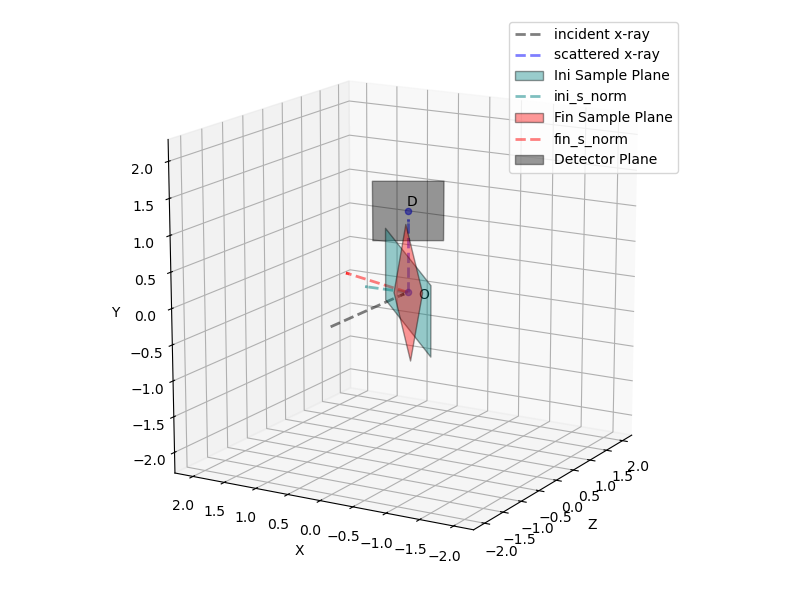

In [13]:
scat_geo_plotter(
    angles={  # Axes ordered from bottom to top, i.e., rotation of a stage affects all ones on top.
        # Goniometer axes
        "Rz_JJ": 0.0,
        "Rx_JJ": 0.0,
        "Ry": -30.0,
        "Rx_TT_L": 0.0,
        "Rz_TT_L": 0.0,
        "Rx_TT_S": 5.0,
        "Rz_TT_S": 10.0,
        # TDMS axes
        "AY": 30.0,  # delta
        "AZ": 0.0,
        "AX": 20.0,  # gamma
    },
    beamline="cdi-nsls2",
    samp_ori_norm=[0.1, 0.3, -1.0],
    samp_ori_u=[1.0, 1.0, 0.0],
    samp_ori_v=[0.0, 1.0, 0.0],
    u_name=None,
    v_name=None,
    flag_inv_norm=False,
    flag_inv_inpl=False,
    flag_plot=True,
    flag_info=True,
)